In [25]:
import numpy as np
import matplotlib.pyplot as plt

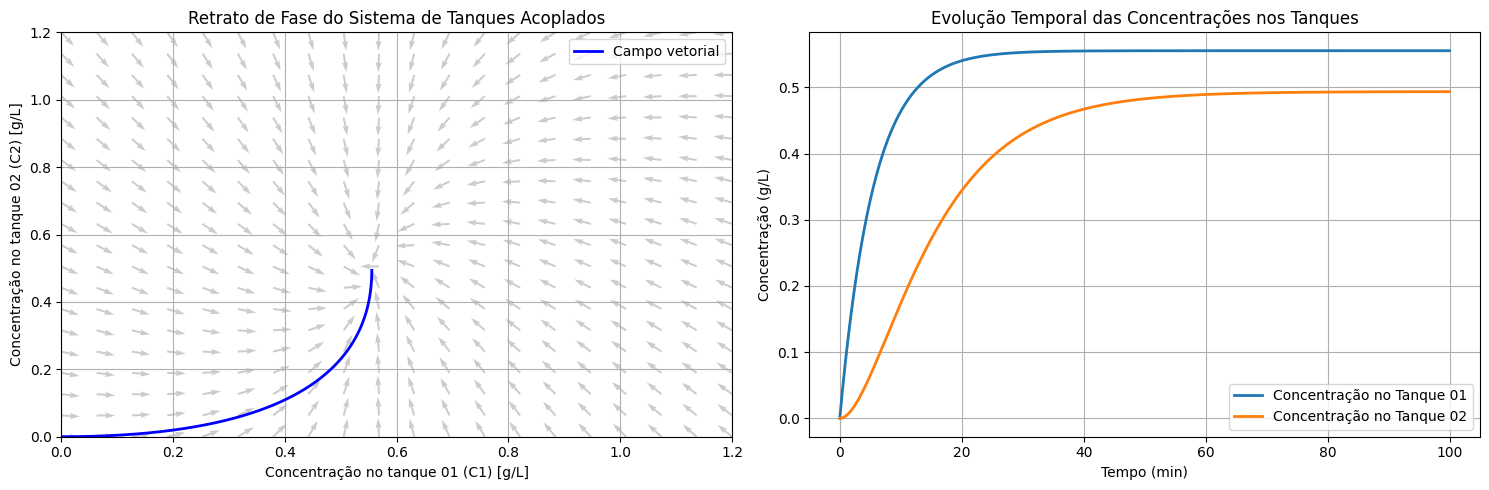

In [26]:
# Código questão 1:

# dados
V1 = 100
V2 = 100
Qin = 10
Q12 = 8
Qout = 1
Cin = 1

t0 = 0
tf = 100
h = 0.01
N = int((tf - t0) / h)

t = np.linspace(t0, tf, N)
C1 = np.zeros(N)
C2 = np.zeros(N)

#valores iniciais do sistema

C1[0] = 0
C2[0] = 0

# for com as derivadas e o euler

for i in range(N - 1):
    derivC1 = (Qin/V1)*(Cin - C1[i]) - (Q12/V1)*C1[i]
    derivC2 = (Q12/V2)*(C1[i] - C2[i]) - (Qout/V2)*C2[i]

    C1[i+1] = C1[i] + h * derivC1
    C2[i+1] = C2[i] + h * derivC2

x = np.linspace(0, 1.2, 20)
y = np.linspace(0, 1.2, 20)

X, Y = np.meshgrid(x, y)

dX = (Qin/V1)*(Cin - X) - (Q12/V1)*X
dY = (Q12/V2)*(X - Y) - (Qout/V2)*Y

norm = np.sqrt(dX**2 + dY**2)
norm[norm == 0] = 1
dXn = dX / norm
dYn = dY / norm

plt.figure(figsize=(15,5))

# Gráfico 1

plt.subplot(1,2,1)
plt.quiver(X, Y, dXn, dYn, color="gray", alpha=0.4)
plt.plot(C1, C2, color="blue", linewidth=2, label="Campo vetorial")
plt.xlabel("Concentração no tanque 01 (C1) [g/L]")
plt.ylabel("Concentração no tanque 02 (C2) [g/L]")
plt.title("Retrato de Fase do Sistema de Tanques Acoplados")
plt.xlim([0, 1.2])
plt.ylim([0, 1.2])
plt.grid(True)
plt.legend()

# Geáfico 2

plt.subplot(1,2,2)
plt.plot(t, C1, label="Concentração no Tanque 01", linewidth=2)
plt.plot(t, C2, label="Concentração no Tanque 02", linewidth=2)
plt.xlabel("Tempo (min)")
plt.ylabel("Concentração (g/L)")
plt.title("Evolução Temporal das Concentrações nos Tanques")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


In [27]:
# Conlusão Questão 1:
""" Diante do exposto nos gráficos, pode-se perceber que o tanque 1, que recebe diretamente o líquido, atinge uma concentração final de valor superior, além de alcançá-la mais rápida do que a do tanque 2,
que justamente depende do primeiro. Além disso, por meio do usoo do método de Euler, e também analisando o retrato de fase, é possível perceber que o sistema é estável e converge para o equilíbrio, determinado, principalmente,
pelas vazões e concentrações iniciais do sistema."""

' Diante do exposto nos gráficos, pode-se perceber que o tanque 1, que recebe diretamente o líquido, atinge uma concentração final de valor superior, além de alcançá-la mais rápida do que a do tanque 2, \nque justamente depende do primeiro. Além disso, por meio do usoo do método de Euler, e também analisando o retrato de fase, é possível perceber que o sistema é estável e converge para o equilíbrio, determinado, principalmente,\npelas vazões e concentrações iniciais do sistema.'

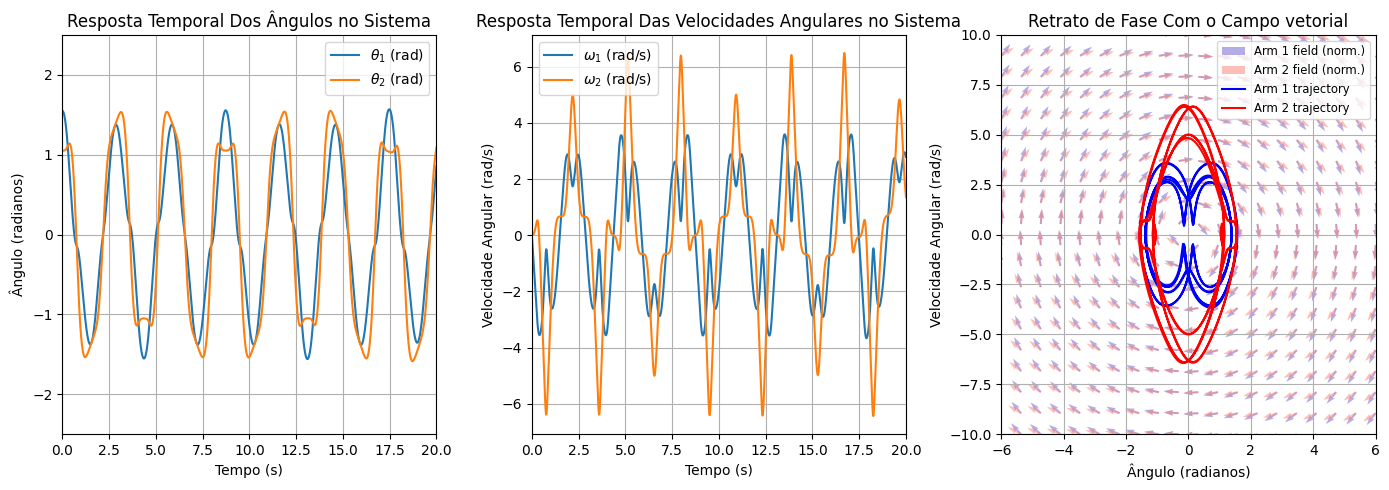

In [28]:
# Código questão 2

# dados

m1, m2 = 1.0, 1.0
l1, l2 = 1.0, 1.0
g = 9.81
t0 = 0
tf = 20
dt = 0.0001
N = int((tf - t0)/dt)
t = np.linspace(t0, tf, N)

theta1 = np.zeros(N)
omega1 = np.zeros(N)
theta2 = np.zeros(N)
omega2 = np.zeros(N)

#valores de teta (ângulo dos pêndulos em rad) e omega (velocidade)

theta1[0] = 1.55
theta2[0] = 1.05
omega1[0] = 0.0
omega2[0] = 0.0

# modelo matemático do pêndulo

def ap_theta1(th1, w1, th2, w2):
    num = -g*(2*m1+m2)*np.sin(th1) - m2*g*np.sin(th1-2*th2) - 2*np.sin(th1-th2)*m2*(w2**2*l2 + w1**2*l1*np.cos(th1-th2))
    den = l1*(2*m1+m2 - m2*np.cos(2*th1-2*th2))
    return num/den

def ap_theta2(th1, w1, th2, w2):
    num = 2*np.sin(th1-th2)*(w1**2*l1*(m1+m2) + g*(m1+m2)*np.cos(th1) + w2**2*l2*m2*np.cos(th1-th2))
    den = l2*(2*m1+m2 - m2*np.cos(2*th1-2*th2))
    return num/den

# euler
for i in range(N - 1):
    a1 = ap_theta1(theta1[i], omega1[i], theta2[i], omega2[i])
    a2 = ap_theta2(theta1[i], omega1[i], theta2[i], omega2[i])
    omega1[i+1] = omega1[i] + dt*a1
    omega2[i+1] = omega2[i] + dt*a2
    theta1[i+1] = theta1[i] + dt*omega1[i]
    theta2[i+1] = theta2[i] + dt*omega2[i]

plt.figure(figsize=(14, 5))

# Gráfico 1 (dxt)

plt.subplot(1,3,1)
plt.plot(t, theta1, label=r'$\theta_1$ (rad)', color='#1f77b4', linewidth=1.5) # Azul padrão
plt.plot(t, theta2, label=r'$\theta_2$ (rad)', color='#ff7f0e', linewidth=1.5) # Laranja padrão
plt.xlim([0,20])
plt.ylim([-2.5, 2.5])
plt.title("Resposta Temporal Dos Ângulos no Sistema")
plt.xlabel("Tempo (s)")
plt.ylabel("Ângulo (radianos)")
plt.grid(True)
plt.legend()

# Gráfico 2 (vxt)

plt.subplot(1,3,2)
plt.plot(t, omega1, label=r'$\omega_1$ (rad/s)', color='#1f77b4', linewidth=1.5)
plt.plot(t, omega2, label=r'$\omega_2$ (rad/s)', color='#ff7f0e', linewidth=1.5)

plt.xlim([0,20])
plt.title("Resposta Temporal Das Velocidades Angulares no Sistema")
plt.xlabel("Tempo (s)")
plt.ylabel("Velocidade Angular (rad/s)")
plt.grid(True)
plt.legend()

# Gráfico 3 (retrato de fase)

plt.subplot(1,3,3)

valores_theta = np.linspace(-6, 6, 20)
valores_omega = np.linspace(-10, 10, 20)
T, W = np.meshgrid(valores_theta, valores_omega)

k1 = 2.0
k2 = 1.0

dT1 = W
dW1 = -k1 * T
dT2 = W
dW2 = -k2 * T

norm1 = np.sqrt(dT1**2 + dW1**2); norm1[norm1==0]=1
norm2 = np.sqrt(dT2**2 + dW2**2); norm2[norm2==0]=1
dT1n, dW1n = dT1/norm1, dW1/norm1
dT2n, dW2n = dT2/norm2, dW2/norm2

plt.quiver(T, W, dT1n, dW1n, color='slateblue', alpha=0.5, scale=25, width=0.005, label='Arm 1 field (norm.)')
plt.quiver(T, W, dT2n, dW2n, color='salmon', alpha=0.5, scale=25, width=0.005, label='Arm 2 field (norm.)')

plt.plot(theta1, omega1, color='blue', linewidth=1.5, label='Arm 1 trajectory')
plt.plot(theta2, omega2, color='red', linewidth=1.5, label='Arm 2 trajectory')

plt.xlim([-6, 6])
plt.ylim([-10, 10])
plt.xlabel("Ângulo (radianos)")
plt.ylabel("Velocidade Angular (rad/s)")
plt.title("Retrato de Fase Com o Campo vetorial")
plt.grid(True)
plt.legend(loc='upper right', fontsize='small')

plt.tight_layout()
plt.show()

In [29]:
# Conclusão questão 2:

""" Ao analisar os resultados obtidos nos gráficos e a implementação do método de euler, pode-se pontuar que o sistema de pêndulo duplo é não linear, sensível às condições iniciais e caótico. As respostas mostram que as variações
são amplas e irregulares, sem periodicidade definida e o diagrama de fases, em especial, é capaz de comprovar que as trajetórias possuem um caráter complexo e não converge para um ponto de equilíbrio."""

' Ao analisar os resultados obtidos nos gráficos e a implementação do método de euler, pode-se pontuar que o sistema de pêndulo duplo é não linear, sensível às condições iniciais e caótico. As respostas mostram que as variações\nsão amplas e irregulares, sem periodicidade definida e o diagrama de fases, em especial, é capaz de comprovar que as trajetórias possuem um caráter complexo e não converge para um ponto de equilíbrio.'